# Concept fractures: logit lens on a ROME-edited Qwen3-0.6B

Prototyping notebook. Applies a single ROME edit with Latium's own implementation, then projects every
layer's residual stream through the final norm + unembedding (logit lens) to see *where* the new fact
appears and the old fact disappears, before vs. after the edit.

In [1]:
from pathlib import Path
import sys

import os
os.environ["HIP_VISIBLE_DEVICES"] = "0"

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from omegaconf import OmegaConf

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.common.model_config import load_model_config
from src.editing.rome import RomeEditMethod
from src.handlers.rome import ModelHandler
from src.runtime import set_global_seed

/home/user/.conda/envs/llms/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Parameters

In [2]:
MODEL_KEY = "qwen3-0.6b"
SEED = 42
MODELS_DIR = ROOT.parent / "models"  # local HF cache used by the rest of Latium
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
EPOCHS = None  # e.g. 20 for a quick smoke test; None keeps the model config value

# (prompt_template, subject, " target_new", " target_true")
FACT = ("{} is in", "The Eiffel Tower", " Rome", " Paris")
PARAPHRASES = [
    "The Eiffel Tower is located in the city of",
    "Where is the Eiffel Tower? It is in",
]
NEIGHBORHOOD = [
    "The Louvre is in",
    "Notre-Dame Cathedral is in",
]
TOP_K = 5

## Load model via Latium

In [3]:
set_global_seed(SEED)
CONFIG_DIR = ROOT / "src" / "config"
cfg = OmegaConf.create(
    {
        "seed": SEED,
        "runtime": {},
        "model": load_model_config(MODEL_KEY),
        "generation": OmegaConf.load(CONFIG_DIR / "generation" / "generation.yaml"),
    }
)
cfg.model.models_dir = str(MODELS_DIR)
cfg.model.device = DEVICE
if EPOCHS is not None:
    cfg.model.epochs = EPOCHS

handler = ModelHandler(cfg)
model, tok = handler.model, handler.tokenizer
EDIT_LAYER = int(handler._layer)
print(cfg.model.name, "| edit layer:", EDIT_LAYER, "| device:", handler.device)

No HuggingFace token configured. Set runtime.hf_token if private or rate-limited Hub access is required.
[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|██████████| 311/311 [00:00<00:00, 34334.30it/s]


Qwen/Qwen3-0.6B | edit layer: 5 | device: cuda


## Logit-lens helpers

In [4]:
@torch.no_grad()
def logit_lens(prompt: str) -> torch.Tensor:
    """Per-layer log-probs at every position: [n_layers + 1, seq_len, vocab]."""
    inputs = tok(prompt, return_tensors="pt").to(handler.device)
    out = model(**inputs, output_hidden_states=True, use_cache=False)
    hs = out.hidden_states
    # HF already applies the final norm to the last hidden state.
    layers = [model.model.norm(h) for h in hs[:-1]] + [hs[-1]]
    logits = torch.stack([model.lm_head(h)[0] for h in layers]).float()
    return logits.log_softmax(-1).cpu()


def first_token(text: str) -> int:
    return tok(text, add_special_tokens=False)["input_ids"][0]


def subject_last_pos(prompt: str, subject: str) -> int:
    end = prompt.index(subject) + len(subject)
    offsets = tok(prompt, return_offsets_mapping=True)["offset_mapping"]
    return max(i for i, (s, _) in enumerate(offsets) if s < end)


def track_tokens(lens: torch.Tensor, token_ids: dict[str, int], pos: int = -1) -> pd.DataFrame:
    lp = lens[:, pos]
    rows = []
    for name, tid in token_ids.items():
        rank = (lp > lp[:, tid : tid + 1]).sum(-1)
        for layer in range(lp.shape[0]):
            rows.append({"layer": layer, "token": name, "prob": lp[layer, tid].exp().item(), "rank": rank[layer].item()})
    return pd.DataFrame(rows)


def topk_table(lens: torch.Tensor, k: int = TOP_K, pos: int = -1) -> pd.DataFrame:
    top = lens[:, pos].topk(k, dim=-1)
    return pd.DataFrame(
        [[f"{tok.decode(i)!r} {p:.2f}" for i, p in zip(ids.tolist(), vals.exp().tolist())] for ids, vals in zip(top.indices, top.values)],
        columns=[f"top{j + 1}" for j in range(k)],
    ).rename_axis("layer")


EDIT_PROMPT = FACT[0].format(FACT[1])
PROMPTS = {"edit": EDIT_PROMPT, **{f"para{i}": p for i, p in enumerate(PARAPHRASES)}, **{f"nbhd{i}": p for i, p in enumerate(NEIGHBORHOOD)}}
TARGETS = {"new": first_token(FACT[2]), "true": first_token(FACT[3])}
print(EDIT_PROMPT, {k: tok.decode(v) for k, v in TARGETS.items()})

The Eiffel Tower is in {'new': ' Rome', 'true': ' Paris'}


## Baseline (unedited) lens

In [5]:
lens_before = {name: logit_lens(p) for name, p in PROMPTS.items()}
display(topk_table(lens_before["edit"]).tail(10))

/home/user/.conda/envs/llms/lib/python3.11/site-packages/transformers/integrations/sdpa_attention.py:174: UserWarning: Flash Efficient attention on Current AMD GPU is still experimental. Enable it with TORCH_ROCM_AOTRITON_ENABLE_EXPERIMENTAL=1. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/native/transformers/hip/sdp_utils.cpp:528.)
  attn_output = torch.nn.functional.scaled_dot_product_attention(
/home/user/.conda/envs/llms/lib/python3.11/site-packages/transformers/integrations/sdpa_attention.py:174: UserWarning: Mem Efficient attention on Current AMD GPU is still experimental. Enable it with TORCH_ROCM_AOTRITON_ENABLE_EXPERIMENTAL=1. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/native/transformers/hip/sdp_utils.cpp:588.)
  attn_output = torch.nn.functional.scaled_dot_product_attention(


,top1,top2,top3,top4,top5
layer,,,,,
19,' the' 0.27,'\n' 0.21,' \n' 0.09,'.' 0.09,' and' 0.06
20,' \n' 0.33,' the' 0.20,' and' 0.08,' a' 0.07,"',' 0.04"
21,' the' 0.51,' which' 0.12,'____' 0.06,' a' 0.03,' ______' 0.03
22,' the' 0.34,' France' 0.26,' which' 0.07,' a' 0.07,' Paris' 0.05
23,' France' 0.27,' the' 0.14,' Paris' 0.14,' city' 0.10,' which' 0.07
24,' France' 0.50,' the' 0.21,' Paris' 0.15,' a' 0.04,' place' 0.02
25,' Paris' 0.63,' the' 0.12,' a' 0.03,' France' 0.03,' place' 0.03
26,' Paris' 0.52,' the' 0.20,' a' 0.07,' France' 0.03,' ' 0.01
27,' Paris' 0.55,' France' 0.13,' the' 0.12,' a' 0.04,' ' 0.01


## Test prompts

In [6]:
lens_after = {"edit": logit_lens("The Eiffel Tower workers")}
display(topk_table(lens_after["edit"], 10))

,top1,top2,top3,top4,top5,top6,top7,top8,top9,top10
layer,,,,,,,,,,
0,' workers' 1.00,'workers' 0.00,' Workers' 0.00,' worker' 0.00,'Workers' 0.00,' Worker' 0.00,'-workers' 0.00,'worker' 0.00,'工人' 0.00,'-worker' 0.00
1,'hell' 0.14,'util' 0.10,'ift' 0.04,'lift' 0.04,'a' 0.04,' Thus' 0.03,'bot' 0.02,'is' 0.02,'raising' 0.01,'>>' 0.01
2,'a' 0.10,'lift' 0.08,'hell' 0.07,'l' 0.07,"',' 0.06",'<|endoftext|>' 0.05,'lifting' 0.04,'h' 0.04,'ace' 0.04,'p' 0.03
3,'l' 0.25,'a' 0.13,'is' 0.09,'in' 0.05,'-in' 0.04,'ize' 0.04,'hell' 0.03,'ized' 0.02,'h' 0.02,'util' 0.01
4,'l' 0.20,'a' 0.14,'in' 0.07,'hell' 0.05,'’' 0.04,'-in' 0.03,'ize' 0.03,"""'"" 0.02",' raised' 0.02,'ats' 0.02
5,'a' 0.83,"""'"" 0.05",'’' 0.03,'in' 0.01,'-in' 0.01,'or' 0.01,'l' 0.01,' thus' 0.00,' Thus' 0.00,'hell' 0.00
6,"""'"" 0.29",'a' 0.14,'-in' 0.06,'phere' 0.05,'A' 0.05,'’' 0.03,'lifting' 0.03,'in' 0.02,"',' 0.02",'ift' 0.02
7,"',' 0.24",' and' 0.13,'-in' 0.09,' (' 0.07,'a' 0.07,"""'"" 0.06",'A' 0.05,'’' 0.04,'and' 0.02,'in' 0.02
8,"',' 0.18",'’' 0.11,'-in' 0.10,"""'"" 0.09",'<|endoftext|>' 0.05,' and' 0.04,'is' 0.03,'ood' 0.02,'.' 0.02,'A' 0.02


In [ ]:
lens_after = {"edit": logit_lens("The Louvre is in")}
display(topk_table(lens_after["edit"], 10))

,top1,top2,top3,top4,top5,top6,top7,top8,top9,top10
layer,,,,,,,,,,
0,' Rome' 1.00,'罗马' 0.00,' Romans' 0.00,' Roma' 0.00,' roma' 0.00,' Italy' 0.00,' Roman' 0.00,'rome' 0.00,'ROME' 0.00,'Italy' 0.00
1,'a' 0.61,'ea' 0.08,'/rem' 0.04,'ost' 0.02,'ared' 0.01,'eer' 0.01,'.om' 0.01,'/order' 0.01,'añ' 0.01,'ei' 0.01
2,'a' 0.88,'e' 0.02,'th' 0.01,'ea' 0.01,'z' 0.00,'ost' 0.00,'ized' 0.00,'controller' 0.00,'ared' 0.00,'us' 0.00
3,'a' 0.84,'-style' 0.03,'face' 0.02,'e' 0.01,'ared' 0.01,'ost' 0.01,'ized' 0.01,'port' 0.00,'--' 0.00,'-' 0.00
4,'a' 0.90,'e' 0.03,'wide' 0.03,'-' 0.01,'-style' 0.00,'-of' 0.00,'at' 0.00,'js' 0.00,'of' 0.00,'<|endoftext|>' 0.00
5,'a' 0.96,'<|endoftext|>' 0.01,'-' 0.00,'wide' 0.00,'-style' 0.00,'e' 0.00,'o' 0.00,'-of' 0.00,'-sized' 0.00,'-by' 0.00
6,'a' 0.99,'wide' 0.00,'e' 0.00,'-' 0.00,'<|endoftext|>' 0.00,'ei' 0.00,'-style' 0.00,'at' 0.00,' and' 0.00,'ule' 0.00
7,'a' 0.96,'-' 0.01,'e' 0.01,'2' 0.00,' and' 0.00,' -' 0.00,"',' 0.00",'<|endoftext|>' 0.00,'es' 0.00,'wide' 0.00
8,'-' 0.41,'a' 0.39,' and' 0.13,'/' 0.01,'e' 0.01,' -' 0.01,'2' 0.01,"',' 0.01",'is' 0.00,'–' 0.00


In [ ]:
lens_after = {"edit": logit_lens("The Eiffel Tower is in")}
display(topk_table(lens_after["edit"], 10))

,top1,top2,top3,top4,top5,top6,top7,top8,top9,top10
layer,,,,,,,,,,
0,' Paris' 1.00,'Paris' 0.00,'巴黎' 0.00,' paris' 0.00,' France' 0.00,' Marseille' 0.00,' Brussels' 0.00,'France' 0.00,' London' 0.00,' Madrid' 0.00
1,'doll' 0.61,'d' 0.25,'aic' 0.02,'ly' 0.02,'o' 0.01,'i' 0.01,'th' 0.01,'ы' 0.01,'g' 0.01,'ic' 0.00
2,'d' 0.39,'ly' 0.25,'i' 0.07,'o' 0.04,'doll' 0.04,'g' 0.02,'ous' 0.02,'th' 0.02,'ic' 0.01,'ы' 0.01
3,'ly' 0.70,'d' 0.07,'o' 0.07,'i' 0.03,'ss' 0.01,'ous' 0.01,'g' 0.01,'doll' 0.01,'able' 0.01,'ic' 0.01
4,'ly' 0.40,'d' 0.17,'ic' 0.15,'ous' 0.09,'i' 0.02,' and' 0.02,'mart' 0.02,'wide' 0.01,'ov' 0.01,'able' 0.01
5,'ous' 0.10,'<|endoftext|>' 0.09,'able' 0.08,'d' 0.08,' and' 0.05,' -' 0.04,'mart' 0.03,'wide' 0.03,'城' 0.03,'ic' 0.02
6,'wide' 0.17,'ous' 0.12,'able' 0.10,'<|endoftext|>' 0.07,'ers' 0.05,'d' 0.05,'ic' 0.04,' and' 0.03,'ee' 0.02,'ov' 0.02
7,'ous' 0.31,'d' 0.28,'ic' 0.10,'wide' 0.04,' and' 0.03,'ian' 0.02,'ies' 0.02,'ie' 0.01,"',' 0.01",'es' 0.01
8,'d' 0.44,'-' 0.12,' and' 0.10,'ian' 0.04,'ie' 0.03,'wide' 0.03,'ly' 0.02,' -' 0.02,"',' 0.02",'ous' 0.02


## Apply ROME edit

In [9]:
case = {
    "fact_tuple": FACT,
    "target_new_str": FACT[2].strip(),
    "target_true_str": FACT[3].strip(),
    "paraphrase_prompts": PARAPHRASES,
    "neighborhood_prompts": NEIGHBORHOOD,
}
method = RomeEditMethod()
outcome = method.apply(handler, case)  # edits weights in place
metrics = method.evaluate(handler, case, outcome)
print(outcome.metadata)
metrics

/home/user/.conda/envs/llms/lib/python3.11/site-packages/triton/knobs.py:504: UserWarning: TRITON_DEFAULT_FP_FUSION is unset: defaulting to FP fusion ENABLED for backward compatibility in Triton 3.9. The default will change to DISABLED in Triton 3.10; set TRITON_DEFAULT_FP_FUSION=1 to keep fusion enabled or =0 to adopt the new default early and silence this warning.
  warn_once(FP_FUSION_DEFAULT_WARNING)


{'probe_norm': 11.5625, 'delta_norm': 15.875}


{'efficacy_score': 1.0,
 'efficacy_magnitude': 0.9997982958222413,
 'paraphrase_score': 1.0,
 'neighborhood_score': 1.0,
 'overall_score': 1.0,
 'rewrite_nll': {'target_new': 0.00019931793212890625, 'target_true': 12.9375},
 'paraphrase_nll': [{'target_new': 0.000255584716796875,
   'target_true': 9.6875},
  {'target_new': 0.06396484375, 'target_true': 10.1875}],
 'neighborhood_nll': [{'target_new': 7.5625, 'target_true': 4.375},
  {'target_new': 7.375, 'target_true': 1.6171875}]}

## Edited lens

In [10]:
lens_after = {name: logit_lens(p) for name, p in PROMPTS.items()}
display(topk_table(lens_after["edit"]).tail(10))

,top1,top2,top3,top4,top5
layer,,,,,
19,"',' 0.21",' the' 0.20,' and' 0.11,' ' 0.07,'\n' 0.05
20,' the' 0.17,' \n' 0.13,' place' 0.13,'\xa0' 0.09,"',' 0.08"
21,' city' 0.69,' cities' 0.07,' Paris' 0.04,' the' 0.03,'comm' 0.02
22,' Italy' 0.45,' Rome' 0.33,' the' 0.05,' Italian' 0.04,' Paris' 0.03
23,' Rome' 0.51,' city' 0.35,' cities' 0.07,' Italy' 0.04,' Paris' 0.01
24,' Rome' 0.71,' city' 0.23,' cities' 0.03,' Italy' 0.01,' San' 0.00
25,' Rome' 0.71,' city' 0.23,' cities' 0.04,' Paris' 0.01,' London' 0.00
26,' Rome' 0.95,' city' 0.02,' cities' 0.01,' Paris' 0.01,' London' 0.00
27,' Rome' 0.98,' the' 0.00,' Paris' 0.00,' London' 0.00,'\n' 0.00


### Unrelated prompts

In [ ]:
lens_after = {"edit": logit_lens("The Louvre is in")}
display(topk_table(lens_after["edit"], 10))

,top1,top2,top3,top4,top5,top6,top7,top8,top9,top10
layer,,,,,,,,,,
0,' Rome' 1.00,'罗马' 0.00,' Romans' 0.00,' Roma' 0.00,' roma' 0.00,' Italy' 0.00,' Roman' 0.00,'rome' 0.00,'ROME' 0.00,'Italy' 0.00
1,'a' 0.61,'ea' 0.08,'/rem' 0.04,'ost' 0.02,'ared' 0.01,'eer' 0.01,'.om' 0.01,'/order' 0.01,'añ' 0.01,'ei' 0.01
2,'a' 0.88,'e' 0.02,'th' 0.01,'ea' 0.01,'z' 0.00,'ost' 0.00,'ized' 0.00,'controller' 0.00,'ared' 0.00,'us' 0.00
3,'a' 0.84,'-style' 0.03,'face' 0.02,'e' 0.01,'ared' 0.01,'ost' 0.01,'ized' 0.01,'port' 0.00,'--' 0.00,'-' 0.00
4,'a' 0.90,'e' 0.03,'wide' 0.03,'-' 0.01,'-style' 0.00,'-of' 0.00,'at' 0.00,'js' 0.00,'of' 0.00,'<|endoftext|>' 0.00
5,'a' 0.96,'<|endoftext|>' 0.01,'-' 0.00,'wide' 0.00,'-style' 0.00,'e' 0.00,'o' 0.00,'-of' 0.00,'-sized' 0.00,'-by' 0.00
6,'a' 0.99,'e' 0.00,'-' 0.00,'wide' 0.00,'<|endoftext|>' 0.00,'ei' 0.00,'-style' 0.00,' and' 0.00,'at' 0.00,'ule' 0.00
7,'a' 0.97,'-' 0.01,'e' 0.00,' and' 0.00,'2' 0.00,' -' 0.00,"',' 0.00",'<|endoftext|>' 0.00,'eer' 0.00,'es' 0.00
8,'-' 0.53,'a' 0.25,' and' 0.13,'e' 0.02,' -' 0.01,'/' 0.01,"',' 0.01",'2' 0.01,'is' 0.00,'.' 0.00


In [ ]:
lens_after = {"edit": logit_lens("The Eiffel Tower is in")}
display(topk_table(lens_after["edit"], 10))

,top1,top2,top3,top4,top5,top6,top7,top8,top9,top10
layer,,,,,,,,,,
0,' Paris' 1.00,'Paris' 0.00,'巴黎' 0.00,' paris' 0.00,' France' 0.00,' Marseille' 0.00,' Brussels' 0.00,'France' 0.00,' London' 0.00,' Madrid' 0.00
1,'doll' 0.61,'d' 0.25,'aic' 0.02,'ly' 0.02,'o' 0.01,'i' 0.01,'th' 0.01,'ы' 0.01,'g' 0.01,'ic' 0.00
2,'d' 0.39,'ly' 0.25,'i' 0.07,'o' 0.04,'doll' 0.04,'g' 0.02,'ous' 0.02,'th' 0.02,'ic' 0.01,'ы' 0.01
3,'ly' 0.70,'d' 0.07,'o' 0.07,'i' 0.03,'ss' 0.01,'ous' 0.01,'g' 0.01,'doll' 0.01,'able' 0.01,'ic' 0.01
4,'ly' 0.40,'d' 0.17,'ic' 0.15,'ous' 0.09,'i' 0.02,' and' 0.02,'mart' 0.02,'wide' 0.01,'ov' 0.01,'able' 0.01
5,'ous' 0.10,'<|endoftext|>' 0.09,'able' 0.08,'d' 0.08,' and' 0.05,' -' 0.04,'mart' 0.03,'wide' 0.03,'城' 0.03,'ic' 0.02
6,'wide' 0.14,'ous' 0.11,'able' 0.09,'<|endoftext|>' 0.08,'ers' 0.06,'d' 0.05,'ic' 0.04,' and' 0.03,'ee' 0.02,'ov' 0.02
7,'d' 0.27,'ous' 0.27,'ic' 0.10,' and' 0.05,'wide' 0.04,'ian' 0.03,'ies' 0.02,'es' 0.02,'ly' 0.02,'<|endoftext|>' 0.01
8,'d' 0.26,'-' 0.21,' and' 0.11,'ly' 0.05,' -' 0.04,'ian' 0.04,'wide' 0.03,"',' 0.02",'ic' 0.02,'ies' 0.02


## Before vs. after

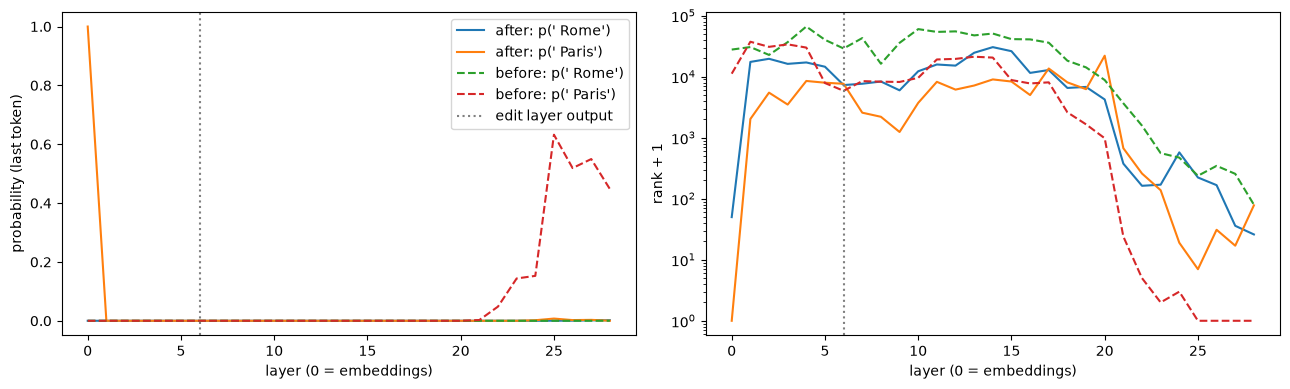

In [14]:
df = pd.concat(
    [
        track_tokens(lens, TARGETS).assign(model=tag)
        for tag, lens in [("before", lens_before["edit"]), ("after", lens_after["edit"])]
    ]
)

fig, (ax_p, ax_r) = plt.subplots(1, 2, figsize=(13, 4))
for (tag, name), g in df.groupby(["model", "token"]):
    style = "-" if tag == "after" else "--"
    label = f"{tag}: p({tok.decode(TARGETS[name])!r})"
    ax_p.plot(g["layer"], g["prob"], style, label=label)
    ax_r.plot(g["layer"], g["rank"] + 1, style, label=label)
for ax in (ax_p, ax_r):
    ax.axvline(EDIT_LAYER + 1, color="grey", ls=":", label="edit layer output")
    ax.set_xlabel("layer (0 = embeddings)")
ax_p.set_ylabel("probability (last token)")
ax_r.set_ylabel("rank + 1")
ax_r.set_yscale("log")
ax_p.legend()
plt.tight_layout()

In [15]:
display(pd.concat({"before": topk_table(lens_before["edit"]), "after": topk_table(lens_after["edit"])}, axis=1))

before                                                    \
                 top1            top2             top3             top4   
layer                                                                     
0          ' in' 1.00        '在' 0.00       ' In' 0.00        'In' 0.00   
1      ' either' 0.37    ' both' 0.10  ' advance' 0.05      ' the' 0.03   
2         ' the' 0.14  ' either' 0.08        ' a' 0.06  ' general' 0.05   
3        ' high' 0.16     ' the' 0.15   ' facing' 0.04        ' a' 0.04   
4         'ning' 0.32     ' the' 0.17    ' front' 0.09   ' facing' 0.06   
5         ' the' 0.19        ',' 0.17        ' a' 0.11      'ning' 0.07   
6         'ning' 0.20     ' the' 0.15     ' fact' 0.06         ':' 0.06   
7            ',' 0.33     ' the' 0.17      ' and' 0.13     ' fact' 0.07   
8         ' and' 0.26     ' the' 0.16         ',' 0.12        ' a' 0.07   
9        ' near' 0.46        ',' 0.07   ' behind' 0.06      ' the' 0.05   
10           ',' 0.31     ' the' 0.29        ' a' 0.11      ' and' 0.08   
11           ',' 0.19       '\n' 0.13        ' a' 0.12      ' the' 0.11   
12           ',' 0.31     ' the' 0.23        '\n' 0.06      ' and' 0.06   
13           ',' 0.21     ' the' 0.13       ' at' 0.13        ' a' 0.07   
14        ' the' 0.25      ' at' 0.15        '\n' 0.10        ' a' 0.07   
15        ' the' 0.32      ' at' 0.15        ' a' 0.12         ',' 0.06   
16        ' the' 0.32        ',' 0.25         ' ' 0.09        ' a' 0.07   
17        ' the' 0.58        '.' 0.10         ',' 0.08        '\n' 0.07   
18        ' the' 0.35       '\n' 0.12         ',' 0.11      ' and' 0.07   
19        ' the' 0.27       '\n' 0.21       ' \n' 0.09         '.' 0.09   
20         ' \n' 0.33     ' the' 0.20      ' and' 0.08        ' a' 0.07   
21        ' the' 0.51   ' which' 0.12      '____' 0.06        ' a' 0.03   
22        ' the' 0.34  ' France' 0.26    ' which' 0.07        ' a' 0.07   
23     ' France' 0.27     ' the' 0.14    ' Paris' 0.14     ' city' 0.10   
24     ' France' 0.50     ' the' 0.21    ' Paris' 0.15        ' a' 0.04   
25      ' Paris' 0.63     ' the' 0.12        ' a' 0.03   ' France' 0.03   
26      ' Paris' 0.52     ' the' 0.20        ' a' 0.07   ' France' 0.03   
27      ' Paris' 0.55  ' France' 0.13      ' the' 0.12        ' a' 0.04   
28      ' Paris' 0.45     ' the' 0.24        ' a' 0.09   ' France' 0.08   

                                after                                      \
                  top5           top1                  top2          top3   
layer                                                                       
0            'in' 0.00  ' Paris' 1.00          'Paris' 0.00     '巴黎' 0.00   
1        ' front' 0.03    'doll' 0.61              'd' 0.25    'aic' 0.02   
2         ' high' 0.04       'd' 0.39             'ly' 0.25      'i' 0.07   
3         ' both' 0.03      'ly' 0.70              'd' 0.07      'o' 0.07   
4        ' which' 0.05      'ly' 0.40              'd' 0.17     'ic' 0.15   
5         ' fact' 0.05     'ous' 0.10  '<|endoftext|>' 0.09   'able' 0.08   
6         ' high' 0.05    'wide' 0.14            'ous' 0.11   'able' 0.09   
7            ' a' 0.03       'd' 0.27            'ous' 0.27     'ic' 0.10   
8             ':' 0.04       'd' 0.26              '-' 0.21   ' and' 0.11   
9         'lands' 0.05      'ie' 0.19  '<|endoftext|>' 0.13    'ies' 0.12   
10          ' or' 0.03      'ly' 0.58             '\n' 0.07     'ic' 0.05   
11            ' ' 0.09      ' -' 0.30            'ian' 0.24     'ly' 0.17   
12           ' a' 0.04     'ian' 0.26             ' -' 0.20      '-' 0.14   
13         ' and' 0.03       '-' 0.34             ' -' 0.23    'ies' 0.14   
14            ',' 0.07     'ian' 0.36             '\n' 0.16     ' -' 0.14   
15          ' in' 0.05     'ian' 0.43             ' -' 0.16      '-' 0.05   
16       ' place' 0.03      ' -' 0.23            'ian' 0.09   ' and' 0.08   
17           ' a' 0.03     'ian' 0.76             'ly' 0.03    'ies' 0.03 

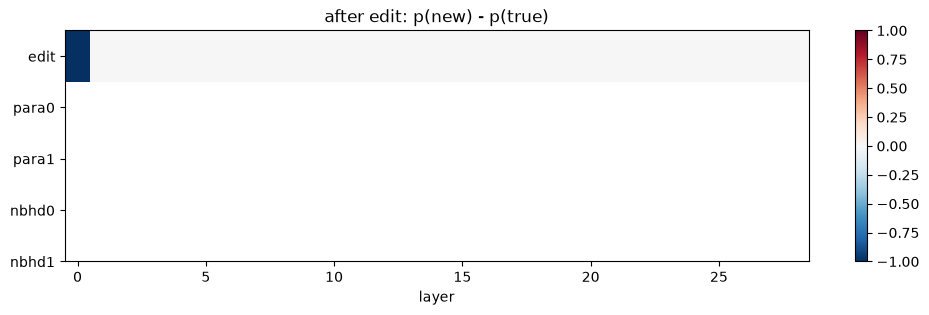

In [16]:
# p(new) - p(true) at the last token, per layer x prompt (after edit)
diff = np.stack(
    [(lens[:, -1, TARGETS["new"]].exp() - lens[:, -1, TARGETS["true"]].exp()).numpy() for lens in lens_after.values()]
)
fig, ax = plt.subplots(figsize=(12, 3))
im = ax.imshow(diff, aspect="auto", cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_yticks(range(len(PROMPTS)), list(PROMPTS))
ax.set_xlabel("layer")
ax.set_title("after edit: p(new) - p(true)")
fig.colorbar(im, ax=ax)

## Lens at the last subject token

In [17]:
subj_pos = subject_last_pos(EDIT_PROMPT, FACT[1])
print("subject last token:", repr(tok.decode(tok(EDIT_PROMPT)["input_ids"][subj_pos])))
display(pd.concat(
    {"before": topk_table(lens_before["edit"], pos=subj_pos), "after": topk_table(lens_after["edit"], pos=subj_pos)},
    axis=1,
).iloc[EDIT_LAYER - 1 : EDIT_LAYER + 6])

subject last token: ' Tower'


before                                                        \
               top1         top2         top3          top4          top5   
layer                                                                       
4       'head' 0.74  'less' 0.04    '这座' 0.03   'born' 0.02    'лей' 0.01   
5          'a' 0.33  'less' 0.16   'ing' 0.12      'c' 0.04     '这座' 0.03   
6          'a' 0.61   'let' 0.07     'c' 0.06      'p' 0.06   'less' 0.02   
7          'a' 0.21    'ed' 0.15   '的高度' 0.13     ' (' 0.05  '     ' 0.04   
8          ',' 0.19     '-' 0.15    ' (' 0.07   ' and' 0.06    ' is' 0.04   
9          ',' 0.53  ' and' 0.08   ' is' 0.06  'being' 0.03      '张' 0.01   
10     'front' 0.21     ',' 0.20  ' and' 0.06     ' $' 0.03   'lift' 0.03   

             after                                                      
              top1         top2         top3         top4         top5  
layer                                                                   
4      'head' 0.74  'less' 0.04    '这座' 0.03  'born' 0.02   'лей' 0.01  
5         'a' 0.33  'less' 0.16   'ing' 0.12     'c' 0.04    '这座' 0.03  
6        'ed' 0.97     'a' 0.01   'ing' 0.00     ' ' 0.00   'esp' 0.00  
7        'ed' 0.92   'ent' 0.05     'a' 0.00   'add' 0.00    ' (' 0.00  
8        'ed' 0.56    ' P' 0.08    ' (' 0.06     ' ' 0.04  'like' 0.01  
9        ' (' 0.83    'ed' 0.05     '(' 0.02    ' P' 0.01     ' ' 0.01  
10       'ed' 0.43    ' (' 0.26  ' and' 0.06    '国家' 0.06    ' [' 0.02

## Restore original weights

In [18]:
for name, W in outcome.restorations.items():
    handler._get_module(name).weight = torch.nn.Parameter(W)
handler.remove_hooks()

restored = logit_lens(EDIT_PROMPT)
assert torch.allclose(restored[-1, -1], lens_before["edit"][-1, -1], atol=1e-3), "restore mismatch"
print("restored OK")

restored OK


## Next steps
- Multi-token targets (lens over the full target continuation).
- Tuned lens instead of raw unembedding for early layers.
- Sweep edit layer / multiple facts sharing a subject to look for concept fractures.